Shape clean5 : (308, 52)
Features candidates : 49
Cibles              : ['taux_log', 'performance.selectivite_pct', 'produit_classe']

NaN dans X après fill : 0
MÉTHODE 1 — Random Forest importance

  Cible 'taux_log' : 263 observations
    Top 5 RF : ['cocatalyseur.type_enc', 'mof.ligand_enc', 'mof.metal_enc', 'cocatalyseur.charge_pct', 'proprietes_electroniques.band_gap_eV']

  Cible 'performance.selectivite_pct' : 97 observations
    Top 5 RF : ['cocatalyseur.charge_pct', 'proprietes_electroniques.band_gap_eV', 'BET_x_duree', 'proprietes_electroniques.HOMO_eV_vs_NHE', 'conditions_reaction.duree_irradiation_h']

  Cible 'produit_classe' : 307 observations
    Top 5 RF : ['conditions_reaction.concentration_catalyseur_g_L', 'BET_x_duree', 'flag.conc_imputee', 'conditions_reaction.solvant_enc', 'proprietes_electroniques.HOMO_eV_vs_NHE']

MÉTHODE 2 — Mutual Information

  Cible 'taux_log' (263 obs) :
    Top 5 MI : ['mof.ligand_enc', 'mof.metal_enc', 'cocatalyseur.type_enc', 'proprietes_

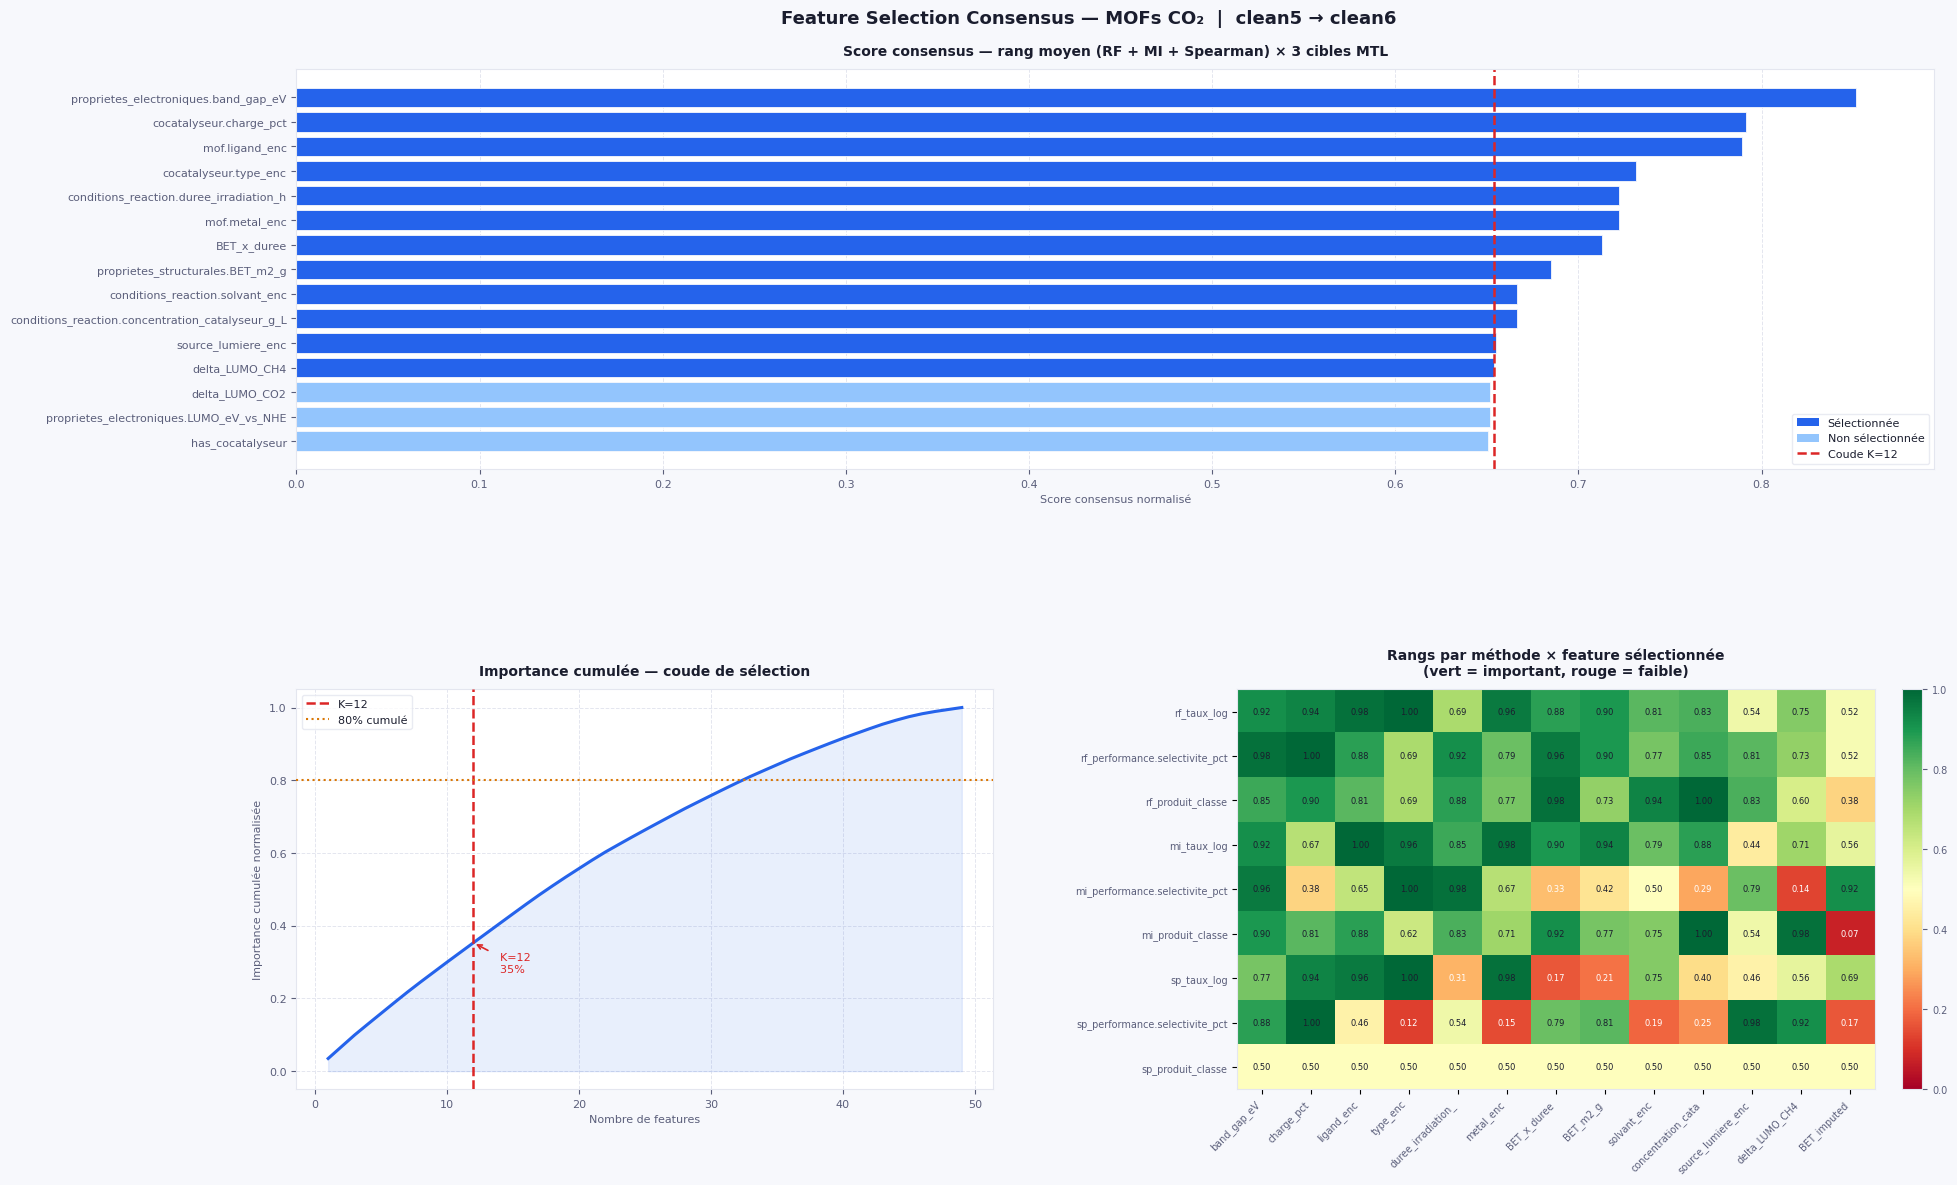

In [1]:
"""
Feature Selection — Consensus 3 méthodes × 3 cibles
Dataset MOFs photocatalyse CO2 — clean5 → clean6

Méthodes :
  1. Random Forest importance (par cible)
  2. Mutual Information (par cible)
  3. Spearman correlation (par cible)

Règle de sélection :
  - Score consensus = rang moyen sur 3 méthodes × 3 cibles
  - Feature gardée si dans top-K (coude courbe cumulée)
  - Maximum 12 features (règle 1/25 lignes sur 300 obs.)
  - band_gap protégé manuellement (signal physique confirmé)
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.patches import Patch
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.feature_selection import mutual_info_regression, mutual_info_classif
from scipy.stats import spearmanr
import warnings
warnings.filterwarnings("ignore")

INPUT   = r"D:\Mes projets\PFE\Project\data\processed\pipeline_outputs\dataset_clean_final.csv"
OUTPUT  = r"D:\Mes projets\PFE\Project\data\processed\pipeline_outputs\feature_selection.csv"
FIG_OUT = r"D:\Mes projets\PFE\Project\data\figures\feature_selection.png"

# ═══════════════════════════════════════════════════════════
# CHARGEMENT
# ═══════════════════════════════════════════════════════════
df = pd.read_csv(INPUT)
print(f"Shape clean5 : {df.shape}")

CIBLES = ["taux_log", "performance.selectivite_pct", "produit_classe"]
CIBLES = [c for c in CIBLES if c in df.columns]

# Features = tout sauf cibles
# On garde binaires ET numériques — RF et MI gèrent les deux
FEATURES = [c for c in df.columns if c not in CIBLES]
print(f"Features candidates : {len(FEATURES)}")
print(f"Cibles              : {CIBLES}\n")

X = df[FEATURES].copy()

# Remplir les NaN résiduels dans X pour RF et MI
# (ne concerne pas les cibles)
for col in X.columns:
    if X[col].isna().any():
        if X[col].dtype == object:
            X[col] = X[col].fillna(X[col].mode().iloc[0])
        else:
            X[col] = X[col].fillna(X[col].median())

print(f"NaN dans X après fill : {X.isna().sum().sum()}")

# ═══════════════════════════════════════════════════════════
# UTILITAIRE — normaliser les scores en rangs [0,1]
# ═══════════════════════════════════════════════════════════
def to_rank_score(scores: pd.Series) -> pd.Series:
    """Convertit des scores bruts en rangs normalisés [0,1]."""
    ranked = scores.rank(ascending=True)
    return (ranked - 1) / (len(ranked) - 1)

# ═══════════════════════════════════════════════════════════
# MÉTHODE 1 — Random Forest importance par cible
# ═══════════════════════════════════════════════════════════
print("=" * 60)
print("MÉTHODE 1 — Random Forest importance")
print("=" * 60)

rf_scores = pd.DataFrame(index=FEATURES)

cible_configs = {
    "taux_log": {
        "type": "regression",
        "model": RandomForestRegressor(
            n_estimators=300, max_features=0.7,
            min_samples_leaf=3, random_state=42, n_jobs=-1
        )
    },
    "performance.selectivite_pct": {
        "type": "regression",
        "model": RandomForestRegressor(
            n_estimators=300, max_features=0.7,
            min_samples_leaf=3, random_state=42, n_jobs=-1
        )
    },
    "produit_classe": {
        "type": "classification",
        "model": RandomForestClassifier(
            n_estimators=300, max_features=0.7,
            min_samples_leaf=3, random_state=42, n_jobs=-1,
            class_weight="balanced"
        )
    },
}

for cible, config in cible_configs.items():
    if cible not in df.columns:
        print(f"  {cible} absent — skip")
        continue

    y = pd.to_numeric(df[cible], errors="coerce") \
        if config["type"] == "regression" \
        else df[cible]

    # Garder uniquement les lignes où y est observé
    mask = y.notna()
    n_obs = mask.sum()
    print(f"\n  Cible '{cible}' : {n_obs} observations")

    if n_obs < 20:
        print(f"    ⚠️  Trop peu d'observations — skip RF")
        rf_scores[f"rf_{cible}"] = 0.0
        continue

    X_fit = X[mask].copy()
    y_fit = y[mask]

    # Encoder y si classification
    if config["type"] == "classification":
        y_fit = y_fit.astype(str)
        from sklearn.preprocessing import LabelEncoder
        le = LabelEncoder()
        y_fit = le.fit_transform(y_fit)

    config["model"].fit(X_fit, y_fit)
    importances = pd.Series(
        config["model"].feature_importances_,
        index=FEATURES
    )
    rf_scores[f"rf_{cible}"] = importances
    print(f"    Top 5 RF : {importances.nlargest(5).index.tolist()}")

# ═══════════════════════════════════════════════════════════
# MÉTHODE 2 — Mutual Information par cible
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("MÉTHODE 2 — Mutual Information")
print("=" * 60)

mi_scores = pd.DataFrame(index=FEATURES)

for cible, config in cible_configs.items():
    if cible not in df.columns:
        continue

    y = pd.to_numeric(df[cible], errors="coerce") \
        if config["type"] == "regression" \
        else df[cible]

    mask = y.notna()
    n_obs = mask.sum()

    if n_obs < 20:
        mi_scores[f"mi_{cible}"] = 0.0
        continue

    X_fit = X[mask].copy()
    y_fit = y[mask]

    if config["type"] == "regression":
        mi = mutual_info_regression(
            X_fit, y_fit.astype(float),
            random_state=42
        )
    else:
        from sklearn.preprocessing import LabelEncoder
        le = LabelEncoder()
        y_enc = le.fit_transform(y_fit.astype(str))
        mi = mutual_info_classif(
            X_fit, y_enc,
            random_state=42
        )

    mi_series = pd.Series(mi, index=FEATURES)
    mi_scores[f"mi_{cible}"] = mi_series
    print(f"\n  Cible '{cible}' ({n_obs} obs) :")
    print(f"    Top 5 MI : {mi_series.nlargest(5).index.tolist()}")

# ═══════════════════════════════════════════════════════════
# MÉTHODE 3 — Spearman correlation |r| par cible
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("MÉTHODE 3 — Spearman |r| par cible")
print("=" * 60)

sp_scores = pd.DataFrame(index=FEATURES)

for cible in CIBLES:
    y = pd.to_numeric(df[cible], errors="coerce")
    if y.isna().all():
        sp_scores[f"sp_{cible}"] = 0.0
        continue

    mask = y.notna()
    sp_vals = {}
    for feat in FEATURES:
        x_feat = pd.to_numeric(X[feat], errors="coerce")
        combined_mask = mask & x_feat.notna()
        if combined_mask.sum() < 10:
            sp_vals[feat] = 0.0
            continue
        r, _ = spearmanr(x_feat[combined_mask], y[combined_mask])
        sp_vals[feat] = abs(r) if not np.isnan(r) else 0.0

    sp_series = pd.Series(sp_vals)
    sp_scores[f"sp_{cible}"] = sp_series
    n_obs = mask.sum()
    print(f"\n  Cible '{cible}' ({n_obs} obs) :")
    print(f"    Top 5 Spearman : {sp_series.nlargest(5).index.tolist()}")

# ═══════════════════════════════════════════════════════════
# SCORE CONSENSUS — rang moyen normalisé
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("SCORE CONSENSUS")
print("=" * 60)

# Combiner toutes les colonnes de scores
all_scores = pd.concat([rf_scores, mi_scores, sp_scores], axis=1).fillna(0)

# Normaliser chaque colonne en rangs [0,1]
all_ranks = all_scores.apply(to_rank_score, axis=0)

# Score final = moyenne des rangs sur toutes les colonnes disponibles
consensus = all_ranks.mean(axis=1).sort_values(ascending=False)
consensus.name = "consensus_score"

print(f"\nTop 15 features par score consensus :")
print(f"\n  {'Rang':<5} {'Feature':<50} {'Score':>8}")
print(f"  {'-'*65}")
for i, (feat, score) in enumerate(consensus.head(15).items()):
    print(f"  {i+1:<5} {feat:<50} {score:>8.4f}")

# ═══════════════════════════════════════════════════════════
# SÉLECTION — coude de la courbe cumulée + protection band_gap
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("SÉLECTION FINALE")
print("=" * 60)

# Courbe cumulée normalisée
cumsum = consensus.cumsum() / consensus.sum()

# Coude : première feature qui fait dépasser 80% de l'importance cumulée
coude_idx = int((cumsum < 0.80).sum()) + 1
coude_idx = max(6, min(coude_idx, 12))   # borné entre 6 et 12
print(f"\n  Coude détecté à K={coude_idx} features (80% importance cumulée)")

selected = consensus.head(coude_idx).index.tolist()

# Protection physique : band_gap doit être présent
PROTECTED = [
    "proprietes_electroniques.band_gap_eV",   # signal physique -0.26 vs taux
    "proprietes_structurales.BET_m2_g",       # clé pour SHAP structurel
]
for feat in PROTECTED:
    if feat in consensus.index and feat not in selected:
        selected.append(feat)
        print(f"  ✅ '{feat}' ajouté (feature protégée physiquement)")

# Toujours garder les flags d'imputation avec leurs features
FLAGS_MAP = {
    "proprietes_structurales.BET_m2_g": "flag.BET_imputed",
    "proprietes_electroniques.band_gap_eV": "flag_band_gap_imputed",
}
for feat, flag in FLAGS_MAP.items():
    if feat in selected and flag in FEATURES and flag not in selected:
        selected.append(flag)
        print(f"  ✅ '{flag}' ajouté (flag de '{feat}')")

print(f"\n  Features sélectionnées ({len(selected)}) :")
for i, f in enumerate(selected):
    score = consensus.get(f, 0)
    print(f"    {i+1:2d}. {f:<50} score={score:.4f}")

# ═══════════════════════════════════════════════════════════
# VISUALISATION
# ═══════════════════════════════════════════════════════════
# ── Palette light theme ───────────────────────────────────
BG_FIG   = "#f7f8fc"   # fond figure
BG_AX    = "#ffffff"   # fond axes
COL_GRID = "#e4e6ef"   # grille
COL_TEXT = "#1a1d2e"   # titres
COL_TICK = "#5a5e7a"   # labels axes
COL_SEL  = "#2563eb"   # feature sélectionnée (bleu vif)
COL_NON  = "#93c5fd"   # feature non sélectionnée (bleu clair)
COL_LINE = "#dc2626"   # ligne coude (rouge)
COL_REF  = "#d97706"   # ligne 80% (orange)
COL_CURVE= "#2563eb"   # courbe cumulée
 
tw   = dict(color=COL_TEXT, fontsize=10, fontweight="bold", pad=10)
lk   = dict(color=COL_TICK, fontsize=8)
tk_p = dict(colors=COL_TICK, labelsize=8)
 
fig = plt.figure(figsize=(18, 12))
fig.patch.set_facecolor(BG_FIG)
 
gs = gridspec.GridSpec(
    2, 2, figure=fig,
    hspace=0.55, wspace=0.35,
    left=0.06, right=0.97,
    top=0.92, bottom=0.07
)
 
# ── 1. Score consensus top 15 (barre horizontale) ─────────
ax1 = fig.add_subplot(gs[0, :])
ax1.set_facecolor(BG_AX)
 
top15  = consensus.head(15)
colors = [COL_SEL if f in selected else COL_NON for f in top15.index]
 
ax1.barh(
    range(len(top15)), top15.values,
    color=colors, edgecolor=BG_FIG, linewidth=0.6
)
ax1.set_yticks(range(len(top15)))
ax1.set_yticklabels(top15.index, fontsize=8, color=COL_TICK)
ax1.invert_yaxis()
ax1.set_title(
    "Score consensus — rang moyen (RF + MI + Spearman) × 3 cibles MTL",
    **tw
)
ax1.set_xlabel("Score consensus normalisé", **lk)
ax1.tick_params(**tk_p)
ax1.grid(color=COL_GRID, linewidth=0.7, linestyle="--", axis="x", zorder=0)
ax1.set_axisbelow(True)
 
ax1.axvline(
    consensus.iloc[coude_idx - 1],
    color=COL_LINE, linestyle="--", linewidth=1.8,
    label=f"Coude K={coude_idx}"
)
 
legend_el = [
    Patch(facecolor=COL_SEL,  label="Sélectionnée",     edgecolor="none"),
    Patch(facecolor=COL_NON,  label="Non sélectionnée", edgecolor="none"),
    plt.Line2D([0], [0], color=COL_LINE, linestyle="--",
               linewidth=1.8, label=f"Coude K={coude_idx}"),
]
ax1.legend(
    handles=legend_el, fontsize=8,
    facecolor=BG_AX, edgecolor=COL_GRID,
    labelcolor=COL_TEXT, loc="lower right"
)
for spine in ax1.spines.values():
    spine.set_edgecolor(COL_GRID)
 
# ── 2. Courbe d'importance cumulée ────────────────────────
ax2 = fig.add_subplot(gs[1, 0])
ax2.set_facecolor(BG_AX)
 
ax2.plot(
    range(1, len(cumsum) + 1), cumsum.values,
    color=COL_CURVE, linewidth=2.2, zorder=3
)
ax2.fill_between(
    range(1, len(cumsum) + 1), cumsum.values,
    alpha=0.10, color=COL_CURVE
)
ax2.axvline(
    coude_idx, color=COL_LINE, linestyle="--",
    linewidth=1.8, label=f"K={coude_idx}", zorder=4
)
ax2.axhline(
    0.80, color=COL_REF, linestyle=":",
    linewidth=1.5, label="80% cumulé", zorder=4
)
 
# Annoter le point de coude
y_coude = cumsum.iloc[coude_idx - 1]
ax2.annotate(
    f"  K={coude_idx}\n  {y_coude:.0%}",
    xy=(coude_idx, y_coude),
    xytext=(coude_idx + 1.5, y_coude - 0.08),
    fontsize=8, color=COL_LINE,
    arrowprops=dict(arrowstyle="->", color=COL_LINE, lw=1.2)
)
 
ax2.set_title("Importance cumulée — coude de sélection", **tw)
ax2.set_xlabel("Nombre de features", **lk)
ax2.set_ylabel("Importance cumulée normalisée", **lk)
ax2.tick_params(**tk_p)
ax2.grid(color=COL_GRID, linewidth=0.7, linestyle="--", zorder=0)
ax2.set_axisbelow(True)
ax2.legend(
    fontsize=8, facecolor=BG_AX,
    edgecolor=COL_GRID, labelcolor=COL_TEXT
)
for spine in ax2.spines.values():
    spine.set_edgecolor(COL_GRID)
 
# ── 3. Heatmap rangs par méthode × feature sélectionnée ──
ax3 = fig.add_subplot(gs[1, 1])
ax3.set_facecolor(BG_AX)
 
heatmap_data = all_ranks.loc[selected].T
im = ax3.imshow(
    heatmap_data.values,
    aspect="auto", cmap="RdYlGn",
    vmin=0, vmax=1
)
 
ax3.set_xticks(range(len(selected)))
ax3.set_xticklabels(
    [f.split(".")[-1][:18] for f in selected],
    rotation=45, ha="right", fontsize=7, color=COL_TICK
)
ax3.set_yticks(range(len(heatmap_data.index)))
ax3.set_yticklabels(heatmap_data.index, fontsize=7, color=COL_TICK)
ax3.set_title(
    "Rangs par méthode × feature sélectionnée\n(vert = important, rouge = faible)",
    **tw
)
 
cbar = plt.colorbar(im, ax=ax3, fraction=0.046, pad=0.04)
cbar.ax.tick_params(colors=COL_TICK, labelsize=7)
cbar.outline.set_edgecolor(COL_GRID)
 
# Valeurs dans les cellules
for i in range(heatmap_data.shape[0]):
    for j in range(heatmap_data.shape[1]):
        val = heatmap_data.values[i, j]
        txt_color = "white" if val < 0.35 else COL_TEXT
        ax3.text(j, i, f"{val:.2f}",
                 ha="center", va="center",
                 fontsize=6, color=txt_color)
 
for spine in ax3.spines.values():
    spine.set_edgecolor(COL_GRID)
 
# ── Titre global ──────────────────────────────────────────
fig.suptitle(
    "Feature Selection Consensus — MOFs CO₂  |  clean5 → clean6",
    color=COL_TEXT, fontsize=13, fontweight="bold", y=0.97
)
 
plt.savefig(FIG_OUT, dpi=150, bbox_inches="tight",
            facecolor=fig.get_facecolor())
print(f"\nFigure sauvegardée → {FIG_OUT}")
 

# ═══════════════════════════════════════════════════════════
# CONSTRUCTION CLEAN6
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("CONSTRUCTION CLEAN6")
print("=" * 60)

# Features sélectionnées + cibles (cibles jamais dans FEATURES)
cols_final = selected + CIBLES
cols_final = [c for c in cols_final if c in df.columns]

df_clean6 = df[cols_final].copy()
print(f"\n  Shape clean6 : {df_clean6.shape}")
print(f"  Features     : {len(selected)}")
print(f"  Cibles       : {len(CIBLES)}")
print(f"\n  Colonnes finales :")
for c in df_clean6.columns:
    nan_n = df_clean6[c].isna().sum()
    nan_s = f"  ({nan_n} NaN)" if nan_n > 0 else ""
    print(f"    {c}{nan_s}")

df_clean6.to_csv(OUTPUT, index=False)
print(f"\n✅ clean6 sauvegardé → {OUTPUT}")
print(f"\n   Prochaine étape : Architecture MTL → Entraînement → SHAP")

# ═══════════════════════════════════════════════════════════
# RAPPORT TEXTE 
# ═══════════════════════════════════════════════════════════
print("\n" + "=" * 60)
print("RAPPORT FEATURE SELECTION — pour mémoire PFE")
print("=" * 60)
print(f"\nDataset : {len(df)} MOFs · {len(FEATURES)} features candidates")
print(f"Méthodes : RF importance × MI × Spearman Rank · 3 cibles MTL")
print(f"Critère  : top-{coude_idx} features par score consensus (rang moyen)")
print(f"\nFeatures retenues ({len(selected)}) :")
for i, f in enumerate(selected):
    sp_taux = sp_scores.get(f"sp_taux_log", pd.Series()).get(f, 0)
    sp_sel  = sp_scores.get(f"sp_performance.selectivite_pct",
                             pd.Series()).get(f, 0)
    print(f"  {i+1:2d}. {f:<50} "
          f"ρ_taux={sp_taux:+.2f}  ρ_sel={sp_sel:+.2f}")

In [2]:
df_clean6.drop(columns=['flag.BET_imputed'], inplace=True)

df_clean6.to_csv(OUTPUT, index=False)

In [12]:

import mlflow
import json
import re
from pathlib import Path

# Configuration MLflow
MLFLOW_TRACKING_URI = "D:/Mes projets/PFE/Project/mlflow_runs"
MLFLOW_EXPERIMENT_NAME = "MOF_photocatalysis_pipeline"

Path(MLFLOW_TRACKING_URI).mkdir(parents=True, exist_ok=True)
mlflow.set_tracking_uri(f"file:///{MLFLOW_TRACKING_URI}")

experiment = mlflow.get_experiment_by_name(MLFLOW_EXPERIMENT_NAME)
if experiment is None:
    mlflow.create_experiment(
        MLFLOW_EXPERIMENT_NAME,
        artifact_location=f"file:///{MLFLOW_TRACKING_URI}/{MLFLOW_EXPERIMENT_NAME}"
    )
mlflow.set_experiment(MLFLOW_EXPERIMENT_NAME)

print(f"MLflow configure avec l'experience : {MLFLOW_EXPERIMENT_NAME}")
print(f"Tracking URI : {MLFLOW_TRACKING_URI}")

# Fonction pour nettoyer les cles
def clean_param_key(key):
    replacements = {
        '%': 'pct', '$': 'dollar', '@': 'at', '?': 'q',
        '=': 'eq', ';': '', ':': '', '[': '_', ']': '_',
        '(': '_', ')': '_', '{': '_', '}': '_', '|': '_',
        '\\': '_', '/': '_', '+': '_plus_', '*': '_star_',
        '&': '_and_', '#': '_sharp_',
    }
    for old, new in replacements.items():
        key = key.replace(old, new)
    key = re.sub(r'[^a-zA-Z0-9_\-\.\/\s]', '_', key)
    if len(key) > 250:
        key = key[:250]
    return key

# Verifier que les variables existent
required_vars = ['FEATURES', 'selected', 'consensus', 'OUTPUT_DIR', 'FIG_OUT']
for var in required_vars:
    if var not in dir():
        print(f"Warning: La variable '{var}' n'est pas definie. Verifiez que la feature selection a ete executee.")

OUTPUT_DIR = Path("D:/Mes projets/PFE/Project/data/processed/pipeline_outputs")
FIG_OUT = "D:/Mes projets/PFE/Project/data/figures/feature_selection.png"

# Demarrer un run MLflow
with mlflow.start_run(run_name="feature_selection") as run:
    
    print(f"Demarrage du run MLflow : {run.info.run_id}")
    
    # 1. Log des parametres
    mlflow.log_param("initial_features_count", len(FEATURES))
    mlflow.log_param("selected_features_count", len(selected))
    mlflow.log_param("selection_criteria", "consensus_RF_MI_Spearman")
    mlflow.log_param("cumulative_importance_threshold", 0.80)
    
    # 2. Log des features selectionnees
    for i, feat in enumerate(selected):
        clean_feat = clean_param_key(str(feat))
        mlflow.log_param(f"selected_feature_{i+1}", clean_feat)
    
    # 3. Log des scores consensus (top 20)
    for i, (feat, score) in enumerate(consensus.head(20).items()):
        clean_feat = clean_param_key(str(feat))
        mlflow.log_metric(f"consensus_score_{clean_feat}", float(score))
    
    # 4. Log des statistiques globales de selection
    mlflow.log_metric("consensus_mean_top10", float(consensus.head(10).mean()))
    mlflow.log_metric("consensus_mean_selected", float(consensus.head(len(selected)).mean()))
    mlflow.log_metric("consensus_std_selected", float(consensus.head(len(selected)).std()))
    
    # 5. Sauvegarder la figure
    if Path(FIG_OUT).exists():
        mlflow.log_artifact(FIG_OUT)
        print(f"  Figure sauvegardee : {FIG_OUT}")
    
    # 6. Sauvegarder les features selectionnees en JSON
    features_path = OUTPUT_DIR / "selected_features.json"
    with open(features_path, "w") as f:
        json.dump({
            "selected_features": selected,
            "scores": {str(k): float(v) for k, v in consensus.to_dict().items()}
        }, f, indent=2)
    mlflow.log_artifact(str(features_path))
    print(f"  Features JSON sauvegardees : {features_path}")
    
    # 7. Sauvegarder le dataset clean6
    clean6_path = OUTPUT_DIR / "feature_selection.csv"
    if clean6_path.exists():
        mlflow.log_artifact(str(clean6_path))
        print(f"  Dataset clean6 sauvegarde : {clean6_path}")
    
    # 8. Log des correlations avec les cibles (si disponibles)
    try:
        if 'sp_scores' in dir():
            for feat in selected[:15]:
                clean_feat = clean_param_key(str(feat))
                if f"sp_taux_log" in sp_scores.columns:
                    sp_taux = sp_scores.loc[feat, "sp_taux_log"] if feat in sp_scores.index else 0
                    mlflow.log_metric(f"spearman_taux_{clean_feat}", float(sp_taux))
                if f"sp_performance.selectivite_pct" in sp_scores.columns:
                    sp_sel = sp_scores.loc[feat, "sp_performance.selectivite_pct"] if feat in sp_scores.index else 0
                    mlflow.log_metric(f"spearman_selectivite_{clean_feat}", float(sp_sel))
    except Exception as e:
        print(f"  Warning: Could not log spearman correlations: {e}")
    
    # 9. Log des importances RF (si disponibles)
    try:
        if 'rf_scores' in dir():
            for feat in selected[:15]:
                clean_feat = clean_param_key(str(feat))
                if f"rf_taux_log" in rf_scores.columns:
                    rf_score = rf_scores.loc[feat, "rf_taux_log"] if feat in rf_scores.index else 0
                    mlflow.log_metric(f"rf_importance_taux_{clean_feat}", float(rf_score))
    except Exception as e:
        print(f"  Warning: Could not log RF importances: {e}")
    
    # 10. Log des tags
    mlflow.set_tag("pipeline_stage", "feature_selection")
    mlflow.set_tag("data_version", "clean6")
    mlflow.set_tag("selection_method", "consensus_RF_MI_Spearman")
    mlflow.set_tag("n_features_selected", len(selected))
    
    print(f"\nRun MLflow termine avec succes")
    print(f"Run ID : {run.info.run_id}")
    print(f"Pour visualiser : mlflow ui --backend-store-uri file:{MLFLOW_TRACKING_URI}")

MLflow configure avec l'experience : MOF_photocatalysis_pipeline
Tracking URI : D:/Mes projets/PFE/Project/mlflow_runs
Demarrage du run MLflow : dfbeb2bc4ab34f2d8742dbecf486cfef
  Figure sauvegardee : D:/Mes projets/PFE/Project/data/figures/feature_selection.png
  Features JSON sauvegardees : D:\Mes projets\PFE\Project\data\processed\pipeline_outputs\selected_features.json
  Dataset clean6 sauvegarde : D:\Mes projets\PFE\Project\data\processed\pipeline_outputs\feature_selection.csv

Run MLflow termine avec succes
Run ID : dfbeb2bc4ab34f2d8742dbecf486cfef
Pour visualiser : mlflow ui --backend-store-uri file:D:/Mes projets/PFE/Project/mlflow_runs
